# UCS420 Cognitive Computing - Assignment 10

## Heart Health Information Assistant

Name: Vishu Verma

Roll number: 1024170242

My roll number is even, so I have made the **Heart Health Information Assistant**.

The assistant works in four stages: **understand** the query (NLP preprocessing) -> **classify** the intent (TF-IDF + classifier) -> **reason** (rules + concept relationships) -> **retrieve** the answer from the knowledge base.

This is only an information assistant for the assignment. It does not diagnose anything and is not a replacement for a doctor.

In [1]:
import re, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings("ignore")

## 1. Labelled corpus

175 queries, 25 for each of the 7 intents. I wrote them the way a normal person would ask, not in medical language.

In [2]:
corpus = {
    "symptoms": [
        "what are the symptoms of a heart attack",
        "how do i know if i have heart disease",
        "what does chest pain from the heart feel like",
        "is shortness of breath a sign of heart problem",
        "what are the warning signs of heart failure",
        "can heart disease cause swelling in the legs",
        "do women have different heart attack symptoms",
        "what does an irregular heartbeat feel like",
        "is feeling tired all the time a sign of a weak heart",
        "signs that my heart is not healthy",
        "why do i get breathless while climbing stairs",
        "is pain in the left arm related to the heart",
        "what are palpitations",
        "can a heart problem cause dizziness and sweating",
        "what are the early symptoms of blocked arteries",
        "what are the common symptoms of heart disease",
        "how does a heart attack feel",
        "is chest tightness a symptom of heart disease",
        "is jaw pain a sign of a heart attack",
        "what are the symptoms of high blood pressure",
        "does heart disease cause sweating and nausea",
        "why does my heart beat fast sometimes",
        "symptoms of heart failure in old people",
        "is fainting a warning sign of heart problems",
        "what are the symptoms of a silent heart attack",
    ],
    "risk_factors": [
        "what causes heart disease",
        "who is at risk of a heart attack",
        "does smoking increase the risk of heart disease",
        "is high blood pressure bad for the heart",
        "can stress cause heart problems",
        "does heart disease run in families",
        "how does high cholesterol affect the heart",
        "does diabetes increase the chance of heart disease",
        "is obesity a risk factor for heart attack",
        "why do arteries get blocked",
        "is smoking harmful for the heart",
        "does sitting all day increase the risk of heart disease",
        "at what age does the risk of heart attack go up",
        "why are heart attacks common in young people now",
        "are men more likely to get heart disease than women",
        "what are the risk factors for heart disease",
        "what is the main cause of a heart attack",
        "does air pollution increase heart risk",
        "why does diabetes cause heart problems",
        "can high blood pressure cause a heart attack",
        "does family history increase my risk of heart disease",
        "why is smoking a risk factor for heart attack",
        "does belly fat increase the risk of heart disease",
        "what causes high cholesterol",
        "what causes heart failure",
    ],
    "prevention": [
        "how can i prevent heart disease",
        "how to keep my heart healthy",
        "what lifestyle changes reduce the risk of a heart attack",
        "how can i lower my cholesterol naturally",
        "tips to avoid a heart attack",
        "how do i reduce my blood pressure without medicine",
        "will quitting smoking protect my heart",
        "how often should i get a heart checkup",
        "how much sleep is needed for a healthy heart",
        "ways to stop heart disease from getting worse",
        "what habits protect the heart",
        "how can i reduce my chances of getting a heart attack",
        "what should i do to avoid blocked arteries",
        "how to control cholesterol and blood pressure at home",
        "does losing weight help prevent heart disease",
        "how to prevent a heart attack",
        "how can i prevent high blood pressure",
        "what can i do to protect my heart",
        "how to reduce the risk of heart disease",
        "best ways to prevent heart problems at a young age",
        "how do i avoid getting heart disease if it runs in my family",
        "can heart disease be prevented",
        "how to prevent a second heart attack",
        "does managing stress help protect the heart",
        "daily habits to keep the heart healthy",
    ],
    "diet": [
        "what foods are good for the heart",
        "which foods should heart patients avoid",
        "is salt bad for the heart",
        "can i eat eggs if i have high cholesterol",
        "what is a heart healthy diet",
        "are fried foods harmful for the heart",
        "is ghee or butter bad for heart patients",
        "which fruits and vegetables are best for the heart",
        "how much oil should i use in cooking for a healthy heart",
        "is drinking alcohol bad for the heart",
        "what should i eat to lower cholesterol",
        "are nuts and almonds good for the heart",
        "is red meat bad for heart health",
        "how much sugar can a heart patient eat",
        "is tea or coffee harmful for the heart",
        "what should heart patients eat",
        "which food is bad for the heart",
        "is rice or roti better for heart patients",
        "can heart patients eat eggs and chicken",
        "what is the best diet for high blood pressure",
        "which cooking oil is best for the heart",
        "foods to avoid with high cholesterol",
        "is fish good for the heart",
        "can i eat sweets if i have heart disease",
        "how much salt should i eat in a day",
    ],
    "exercise": [
        "what exercise is good for the heart",
        "how much should i walk every day for heart health",
        "is running safe for heart patients",
        "can i go to the gym after a heart attack",
        "how many minutes of exercise do i need in a week",
        "is yoga good for the heart",
        "which workouts make the heart stronger",
        "can i lift weights if i have high blood pressure",
        "is cycling or swimming better for the heart",
        "when should i stop exercising if i have a heart problem",
        "is brisk walking enough exercise for the heart",
        "how do i start exercising after heart surgery",
        "what is the best cardio workout for heart health",
        "can heart patients climb stairs or jog",
        "how long should i work out each day",
        "how much exercise is needed for a healthy heart",
        "which exercise is best for heart patients",
        "is walking good for the heart",
        "can i exercise with high blood pressure",
        "is it safe to exercise with heart disease",
        "how many days a week should i exercise",
        "is jogging or walking better for heart health",
        "can i do gym workouts if i have a heart problem",
        "what exercises should heart patients avoid",
        "does exercise make the heart stronger",
    ],
    "medication": [
        "what medicines are used for heart disease",
        "what do statins do",
        "why is aspirin given to heart patients",
        "what are the side effects of blood pressure tablets",
        "what are beta blockers used for",
        "can i stop taking my heart medicine if i feel fine",
        "what happens if i miss a dose of my blood thinner",
        "what does a blood thinner do",
        "which tablets lower cholesterol",
        "is it safe to take painkillers with heart medicine",
        "do statins have any side effects",
        "which medicines are given for high blood pressure",
        "how long do i have to take heart medicines",
        "can i take aspirin every day",
        "what is nitroglycerin used for",
        "what medicine is given after a heart attack",
        "do i have to take blood pressure tablets for life",
        "what is the use of atorvastatin",
        "what are the side effects of aspirin",
        "can i take two tablets if i forgot a dose",
        "what are the side effects of heart medicines",
        "which medicine is used for chest pain",
        "do blood thinners cause bleeding",
        "what is clopidogrel used for",
        "can i stop statins once my cholesterol is normal",
    ],
    "diagnosis": [
        "what tests are done to check the heart",
        "what is an ecg",
        "what does an echocardiogram show",
        "how is heart disease diagnosed",
        "what is a stress test",
        "what is angiography",
        "what is a normal blood pressure reading",
        "what should my cholesterol level be",
        "what is a lipid profile test",
        "what is a normal resting heart rate",
        "which test shows blockage in the heart",
        "what is a treadmill test",
        "what does a troponin blood test show",
        "how is high blood pressure measured",
        "what is a normal ejection fraction",
        "which test is done to detect heart disease",
        "how is an ecg done",
        "what is an echo test",
        "what is a tmt test",
        "how is a heart attack diagnosed",
        "what blood tests are done for the heart",
        "how is cholesterol tested",
        "what is ct angiography",
        "what is a normal cholesterol level",
        "how do i check my blood pressure at home",
    ],
}

df = pd.DataFrame([(q, intent) for intent, qs in corpus.items() for q in qs], columns=["query", "intent"])
print("Total queries:", len(df))
print(df["intent"].value_counts().to_string())
df.sample(8, random_state=42)

Total queries: 175
intent
symptoms        25
risk_factors    25
prevention      25
diet            25
exercise        25
medication      25
diagnosis       25


,query,intent
156,what is a normal blood pressure reading,diagnosis
145,what are the side effects of heart medicines,medication
101,how much should i walk every day for heart health,exercise
127,why is aspirin given to heart patients,medication
141,do i have to take blood pressure tablets for life,medication
139,what is nitroglycerin used for,medication
42,does air pollution increase heart risk,risk_factors
15,what are the common symptoms of heart disease,symptoms


## 2. Hierarchical taxonomy

5 major categories with 2 or 3 subcategories each. Every intent of the corpus sits under one of the major categories, which is shown after the tree.

In [3]:
taxonomy = {
    "Heart Health": {
        "Heart Conditions": ["Coronary Artery Disease", "Heart Failure", "Arrhythmia"],
        "Symptoms": ["Common Symptoms", "Emergency Warning Signs"],
        "Risk Factors": ["Modifiable (smoking, BP, cholesterol, weight)", "Non-modifiable (age, family history)"],
        "Lifestyle Management": ["Diet", "Exercise", "Prevention Habits"],
        "Medical Care": ["Medication", "Diagnostic Tests"],
    }
}

def show_tree(node, indent=0):
    if isinstance(node, dict):
        for k, v in node.items():
            print("    " * indent + ("|-- " if indent else "") + k)
            show_tree(v, indent + 1)
    else:
        for leaf in node:
            print("    " * indent + "|-- " + leaf)

show_tree(taxonomy)

intent_to_category = {
    "symptoms": "Symptoms",
    "risk_factors": "Risk Factors",
    "prevention": "Lifestyle Management",
    "diet": "Lifestyle Management",
    "exercise": "Lifestyle Management",
    "medication": "Medical Care",
    "diagnosis": "Medical Care",
}
print()
for intent, cat in intent_to_category.items():
    print(f"{intent:13s} -> {cat}")

Heart Health
    |-- Heart Conditions
        |-- Coronary Artery Disease
        |-- Heart Failure
        |-- Arrhythmia
    |-- Symptoms
        |-- Common Symptoms
        |-- Emergency Warning Signs
    |-- Risk Factors
        |-- Modifiable (smoking, BP, cholesterol, weight)
        |-- Non-modifiable (age, family history)
    |-- Lifestyle Management
        |-- Diet
        |-- Exercise
        |-- Prevention Habits
    |-- Medical Care
        |-- Medication
        |-- Diagnostic Tests

symptoms      -> Symptoms
risk_factors  -> Risk Factors
prevention    -> Lifestyle Management
diet          -> Lifestyle Management
exercise      -> Lifestyle Management
medication    -> Medical Care
diagnosis     -> Medical Care


## 3. Domain concepts and relationships

16 concepts and 18 relationships, stored as (subject, relation, object) triples. The assistant uses these later to add related facts to an answer.

In [4]:
relations = [
    ("Coronary Artery Disease", "is a type of", "Heart Disease"),
    ("Heart Failure", "is a type of", "Heart Disease"),
    ("Atherosclerosis", "causes", "Coronary Artery Disease"),
    ("Coronary Artery Disease", "can lead to", "Heart Attack"),
    ("Heart Attack", "can lead to", "Heart Failure"),
    ("High Cholesterol", "causes", "Atherosclerosis"),
    ("High Blood Pressure", "is a risk factor for", "Heart Failure"),
    ("High Blood Pressure", "is a risk factor for", "Coronary Artery Disease"),
    ("Smoking", "is a risk factor for", "Coronary Artery Disease"),
    ("Diabetes", "is a risk factor for", "Coronary Artery Disease"),
    ("Obesity", "is a risk factor for", "High Blood Pressure"),
    ("Chest Pain", "is a symptom of", "Heart Attack"),
    ("Chest Pain", "is a symptom of", "Coronary Artery Disease"),
    ("Exercise", "lowers", "High Blood Pressure"),
    ("Healthy Diet", "lowers", "High Cholesterol"),
    ("Statin", "treats", "High Cholesterol"),
    ("ECG", "detects", "Heart Attack"),
    ("Exercise", "reduces", "Obesity"),
]

concepts = sorted({s for s, _, _ in relations} | {o for _, _, o in relations})
print(len(concepts), "concepts:", concepts)
print(len(relations), "relationships\n")
for s, r, o in relations:
    print(f"{s:24s} --{r}--> {o}")

15 concepts: ['Atherosclerosis', 'Chest Pain', 'Coronary Artery Disease', 'Diabetes', 'ECG', 'Exercise', 'Healthy Diet', 'Heart Attack', 'Heart Disease', 'Heart Failure', 'High Blood Pressure', 'High Cholesterol', 'Obesity', 'Smoking', 'Statin']
18 relationships

Coronary Artery Disease  --is a type of--> Heart Disease
Heart Failure            --is a type of--> Heart Disease
Atherosclerosis          --causes--> Coronary Artery Disease
Coronary Artery Disease  --can lead to--> Heart Attack
Heart Attack             --can lead to--> Heart Failure
High Cholesterol         --causes--> Atherosclerosis
High Blood Pressure      --is a risk factor for--> Heart Failure
High Blood Pressure      --is a risk factor for--> Coronary Artery Disease
Smoking                  --is a risk factor for--> Coronary Artery Disease
Diabetes                 --is a risk factor for--> Coronary Artery Disease
Obesity                  --is a risk factor for--> High Blood Pressure
Chest Pain               --is a symp

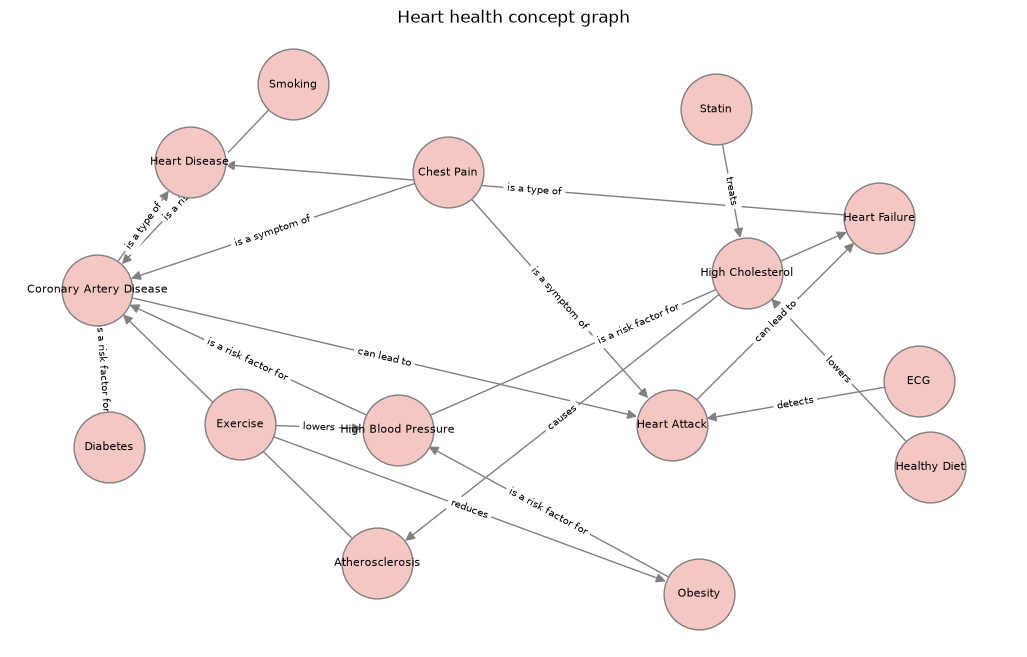

In [5]:
import networkx as nx

G = nx.DiGraph()
for s, r, o in relations:
    G.add_edge(s, o, label=r)

plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, seed=7, k=1.6)
nx.draw_networkx_nodes(G, pos, node_color="#f4c7c3", node_size=2600, edgecolors="gray")
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, arrowsize=14, edge_color="gray", node_size=2600)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
plt.title("Heart health concept graph")
plt.axis("off")
plt.show()

## 4. Text preprocessing

Lowercase -> tokenize -> remove stopwords -> lemmatize.

The WordNet lemmatizer treats every word as a noun by default, so "smoking" and "exercising" would stay as they are. I lemmatize as a verb first and then as a noun, so they become "smoke" and "exercise".

In [6]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

STOP = set(stopwords.words("english"))
lem = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()                                    # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)                           # tokenization
    tokens = [t for t in tokens if t not in STOP]          # stopword removal
    tokens = [lem.lemmatize(lem.lemmatize(t, "v")) for t in tokens]   # lemmatization
    return [t for t in tokens if len(t) > 1]

sample = "Which foods should heart patients avoid?"
low = sample.lower()
tok = word_tokenize(re.sub(r"[^a-z\s]", " ", low))
print("Original   :", sample)
print("Lowercase  :", low)
print("Tokens     :", tok)
print("No stopword:", [t for t in tok if t not in STOP])
print("Lemmatized :", preprocess(sample))

Original   : Which foods should heart patients avoid?
Lowercase  : which foods should heart patients avoid?
Tokens     : ['which', 'foods', 'should', 'heart', 'patients', 'avoid']
No stopword: ['foods', 'heart', 'patients', 'avoid']


Lemmatized : ['food', 'heart', 'patient', 'avoid']


In [7]:
df["clean"] = df["query"].apply(lambda q: " ".join(preprocess(q)))
df.groupby("intent").head(2)[["query", "clean", "intent"]]

,query,clean,intent
0,what are the symptoms of a heart attack,symptom heart attack,symptoms
1,how do i know if i have heart disease,know heart disease,symptoms
25,what causes heart disease,cause heart disease,risk_factors
26,who is at risk of a heart attack,risk heart attack,risk_factors
50,how can i prevent heart disease,prevent heart disease,prevention
51,how to keep my heart healthy,keep heart healthy,prevention
75,what foods are good for the heart,food good heart,diet
76,which foods should heart patients avoid,food heart patient avoid,diet
100,what exercise is good for the heart,exercise good heart,exercise
101,how much should i walk every day for heart health,much walk every day heart health,exercise


## 5. TF-IDF and classifier

75% of the queries are used for training and 25% for testing (stratified, so each intent has queries in both). I tried adding bigrams as well, but with so few queries most bigrams appear only once and the cross validation accuracy went down a little, so I kept single words only.

In [8]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=42)
print("Train:", len(X_train), " Test:", len(X_test))

tfidf = TfidfVectorizer()
tfidf.fit(X_train)
print("TF-IDF features:", len(tfidf.vocabulary_))

row = tfidf.transform([X_train.iloc[0]])
print("\nQuery:", X_train.iloc[0])
print(pd.Series(row.toarray()[0], index=tfidf.get_feature_names_out()).sort_values(ascending=False).head(5).round(3).to_string())

Train: 131  Test: 44
TF-IDF features: 177

Query: much oil use cook healthy heart
oil        0.492
cook       0.492
use        0.421
much       0.405
healthy    0.391


All three classifiers allowed in the question are compared with 5-fold cross validation on the whole corpus, because a test set of 44 queries alone is too small to compare them.

In [9]:
models = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(C=10, max_iter=1000),
    "Linear SVM": LinearSVC(C=1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    pipe = make_pipeline(TfidfVectorizer(), m)
    scores = cross_val_score(pipe, df["clean"], df["intent"], cv=cv)
    pipe.fit(X_train, y_train)
    rows.append({"model": name, "cv accuracy": scores.mean(), "cv std": scores.std(), "test accuracy": pipe.score(X_test, y_test)})
pd.DataFrame(rows).round(3)

,model,cv accuracy,cv std,test accuracy
0,Naive Bayes,0.771,0.065,0.727
1,Logistic Regression,0.794,0.049,0.705
2,Linear SVM,0.806,0.066,0.727


Linear SVM is slightly ahead in cross validation (0.806 against 0.794 for Logistic Regression), but the gap is much smaller than the spread between folds, so the three are practically the same on this data.

I use **Logistic Regression** for the assistant because `predict_proba` gives a probability for every intent, and the low-confidence rule needs that. `LinearSVC` only gives distances from the boundary.

In [10]:
clf = make_pipeline(TfidfVectorizer(), LogisticRegression(C=10, max_iter=1000))
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

## 6. Evaluation

In [11]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay

acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
print(f"Accuracy : {acc:.3f}")
print(f"Precision: {p:.3f} (macro)")
print(f"Recall   : {r:.3f} (macro)")
print(f"F1-score : {f1:.3f} (macro)\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.705
Precision: 0.702 (macro)
Recall   : 0.697 (macro)
F1-score : 0.693 (macro)

              precision    recall  f1-score   support

   diagnosis       0.86      1.00      0.92         6
        diet       0.75      0.50      0.60         6
    exercise       0.60      0.50      0.55         6
  medication       0.88      1.00      0.93         7
  prevention       0.57      0.67      0.62         6
risk_factors       0.43      0.50      0.46         6
    symptoms       0.83      0.71      0.77         7

    accuracy                           0.70        44
   macro avg       0.70      0.70      0.69        44
weighted avg       0.71      0.70      0.70        44



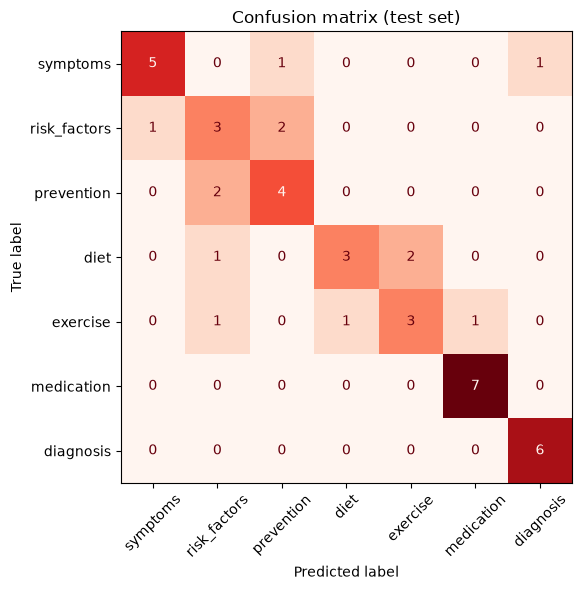

In [12]:
labels = list(corpus.keys())
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Reds", colorbar=False, xticks_rotation=45)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

In [13]:
wrong = pd.DataFrame({"query": df.loc[X_test.index, "query"], "actual": y_test, "predicted": y_pred})
wrong = wrong[wrong["actual"] != wrong["predicted"]]
print("Misclassified test queries:", len(wrong))
wrong

Misclassified test queries: 13


,query,actual,predicted
89,is tea or coffee harmful for the heart,diet,risk_factors
49,what causes heart failure,risk_factors,symptoms
68,how to reduce the risk of heart disease,prevention,risk_factors
97,is fish good for the heart,diet,exercise
102,is running safe for heart patients,exercise,diet
10,why do i get breathless while climbing stairs,symptoms,prevention
107,can i lift weights if i have high blood pressure,exercise,risk_factors
52,what lifestyle changes reduce the risk of a he...,prevention,risk_factors
114,how long should i work out each day,exercise,medication
38,why are heart attacks common in young people now,risk_factors,prevention


- Test accuracy is 0.705 on 44 queries (macro precision 0.70, recall 0.70, F1 0.69). The 5-fold cross validation accuracy of 0.79 is the more reliable number, because one query in the test set is worth more than 2%.
- `diagnosis` and `medication` are the easiest (F1 0.92 and 0.93). They have their own words like "test", "ecg", "tablet", "statin" which do not appear in other intents.
- `risk_factors` and `prevention` are the weakest (F1 0.46 and 0.62) and are mostly confused with each other. Both talk about the same things from two sides: "how to reduce the risk of heart disease" is prevention, but it was predicted as risk_factors because of the word "risk".
- Some mistakes happen because the main word is only in the test set, for example "palpitations", "fish" and "nuts". A bigger corpus would fix these.

For the assistant I retrain the same model on all 175 queries, since there is no reason to keep 44 of them away from the final model.

In [14]:
clf.fit(df["clean"], df["intent"])
vocab = set(clf.named_steps["tfidfvectorizer"].vocabulary_)
print("Final model trained on", len(df), "queries,", len(vocab), "features")

Final model trained on 175 queries, 212 features


## 7. Knowledge base

Each intent has a few entries. Every entry has keywords and an answer. After the intent is predicted, the query is compared with the keywords of every entry of that intent using TF-IDF cosine similarity and the closest entry is returned. TF-IDF is used here too so that a rare word like "ecg" or "statin" counts more than a common one like "test" or "blood". If nothing matches, the first (general) entry is used.

The facts are from WHO, American Heart Association and NHS pages.

In [15]:
kb = {
    "symptoms": [
        {"keywords": "symptom sign know disease unhealthy",
         "answer": "Common symptoms of heart disease are chest pain or pressure (angina), shortness of breath, getting tired easily, palpitations, dizziness and swelling in the feet or ankles. Some people have no symptoms for years, which is why regular checkups matter."},
        {"keywords": "attack warning woman chest pain different arm leave sweat",
         "answer": "Warning signs of a heart attack: pressure or squeezing pain in the centre of the chest that lasts more than a few minutes, pain spreading to the arm, jaw, neck or back, cold sweat, nausea and breathlessness. Women, older people and diabetics often get milder signs like unusual tiredness, nausea or back pain without strong chest pain."},
        {"keywords": "failure swell leg ankle tire weak breath shortness breathless stair",
         "answer": "In heart failure the heart cannot pump enough blood, so fluid collects in the body. The signs are breathlessness on walking or lying flat, swollen feet, ankles or legs, sudden weight gain and constant tiredness."},
        {"keywords": "irregular heartbeat palpitation flutter skip race beat dizziness",
         "answer": "An irregular heartbeat (arrhythmia) feels like fluttering, pounding, a skipped beat or a racing heart. Occasional skipped beats are common, but if it comes with dizziness, fainting or chest pain it needs to be checked by a doctor."},
    ],
    "risk_factors": [
        {"keywords": "cause risk factor who chance sit",
         "answer": "The main risk factors are high blood pressure, high cholesterol, smoking, diabetes, obesity, lack of exercise, unhealthy diet and stress. Age and family history also matter but cannot be changed."},
        {"keywords": "smoke cigarette tobacco",
         "answer": "Smoking damages the lining of the arteries, raises blood pressure and makes blood clot more easily. Smokers have about two to four times the risk of heart disease compared to non-smokers."},
        {"keywords": "high blood pressure cholesterol diabetes obesity weight sugar affect",
         "answer": "High blood pressure makes the heart work harder and damages artery walls. High LDL cholesterol builds up as plaque inside the arteries. Diabetes and obesity speed up both of these, so together they raise the risk of heart attack a lot."},
        {"keywords": "family run gene hereditary age men woman young",
         "answer": "Yes, heart disease can run in families. The risk is higher if a father or brother had it before 55 or a mother or sister before 65. You cannot change this, but controlling the other risk factors still lowers your risk."},
        {"keywords": "stress anxiety tension",
         "answer": "Long term stress raises blood pressure and often leads to smoking, overeating and poor sleep, all of which are bad for the heart. Stress alone is not the main cause but it adds to the risk."},
        {"keywords": "artery block plaque clog",
         "answer": "Arteries get blocked by atherosclerosis. Cholesterol, fat and calcium collect inside the artery wall as plaque, which narrows the artery. If the plaque breaks, a clot forms and can block the blood flow, causing a heart attack."},
    ],
    "prevention": [
        {"keywords": "prevent keep healthy lifestyle change avoid tip stop worse",
         "answer": "To protect your heart: do not smoke, stay active for at least 30 minutes on most days, eat more fruits, vegetables and whole grains, cut down on salt and fried food, keep a healthy weight, sleep well and get your blood pressure, sugar and cholesterol checked regularly."},
        {"keywords": "lower reduce control cholesterol blood pressure naturally without medicine home weight",
         "answer": "Blood pressure and cholesterol can be brought down by eating less salt and saturated fat, eating more fibre (oats, pulses, fruits), exercising regularly, losing extra weight, limiting alcohol and quitting smoking. If the numbers stay high after this, medicine may still be needed."},
        {"keywords": "quit smoke protect",
         "answer": "Yes. After quitting smoking the risk starts falling within weeks, and after about one year the extra risk of coronary heart disease is roughly half that of a person who still smokes."},
        {"keywords": "checkup often screen",
         "answer": "Adults should get blood pressure checked at least once a year and cholesterol every 4 to 6 years. People with diabetes, high BP, a family history or age above 40 should get checked more often, as advised by their doctor."},
        {"keywords": "sleep hour night rest",
         "answer": "Adults need 7 to 9 hours of sleep. Regularly sleeping less than 6 hours is linked with higher blood pressure, weight gain and a higher risk of heart disease."},
    ],
    "diet": [
        {"keywords": "food good healthy diet best fruit vegetable eat lower cholesterol",
         "answer": "A heart healthy diet has plenty of fruits, vegetables, whole grains, pulses, nuts and seeds, with fish or lean protein and small amounts of unsaturated oil. The DASH and Mediterranean diets are the best studied examples."},
        {"keywords": "avoid fry harmful ghee butter junk fat red meat sugar sweet",
         "answer": "Limit fried food, bakery items and packaged snacks (trans fat), processed and red meat, sugary drinks and too much ghee, butter or cream (saturated fat). Small amounts of ghee are fine, but it should not be the main cooking fat."},
        {"keywords": "salt sodium much",
         "answer": "Too much salt raises blood pressure. WHO recommends less than 5 g of salt a day, which is about one teaspoon, including the salt hidden in pickles, papad, chips and packaged food."},
        {"keywords": "egg",
         "answer": "For most people one egg a day is fine. Saturated and trans fat in the overall diet affect blood cholesterol more than the cholesterol in eggs. People with high cholesterol or diabetes should ask their doctor how many they can have."},
        {"keywords": "oil cook",
         "answer": "Use small amounts of unsaturated oils such as mustard, groundnut, sunflower or olive oil, around 4 to 5 teaspoons per person a day. Avoid reusing oil that has already been used for deep frying."},
        {"keywords": "tea coffee caffeine",
         "answer": "For most people 2 to 3 cups of tea or coffee a day is not harmful for the heart. Too much caffeine can cause palpitations in some people, and the sugar and cream added to it matter more than the tea or coffee itself."},
        {"keywords": "nut almond walnut seed",
         "answer": "Yes. A small handful (about 30 g) of unsalted nuts like almonds and walnuts a day gives healthy fats and fibre and is linked with lower LDL cholesterol."},
        {"keywords": "alcohol drink beer wine",
         "answer": "Alcohol raises blood pressure and triglycerides and can cause an irregular heartbeat. It is not recommended to start drinking for heart health, and people who drink should keep it as low as possible."},
    ],
    "exercise": [
        {"keywords": "exercise good workout strong minute week many cycle swim run cardio long best",
         "answer": "Aim for at least 150 minutes of moderate exercise (brisk walking, cycling, swimming) or 75 minutes of vigorous exercise every week, plus muscle strengthening on 2 days. Any aerobic activity you can do regularly is good, there is no single best one."},
        {"keywords": "walk brisk enough step",
         "answer": "A brisk walk of about 30 minutes, 5 days a week, is enough to meet the basic target. It can also be split into three 10 minute walks."},
        {"keywords": "patient gym attack safe after surgery start climb jog",
         "answer": "Most heart patients can and should exercise, but only after the doctor clears it. After a heart attack it usually starts with a cardiac rehabilitation programme: slow walking first, then increasing gradually over weeks."},
        {"keywords": "lift weight high blood pressure",
         "answer": "Light to moderate weight training is fine if blood pressure is under control. Avoid very heavy weights and do not hold your breath while lifting, because that pushes the pressure up sharply."},
        {"keywords": "stop problem",
         "answer": "Stop exercising and rest if you get chest pain or tightness, unusual breathlessness, dizziness or a very fast or irregular heartbeat. If it does not settle in a few minutes, get medical help."},
        {"keywords": "yoga meditation",
         "answer": "Yoga helps with stress, flexibility and blood pressure. It is a good addition, but it should be combined with some aerobic activity like walking."},
    ],
    "medication": [
        {"keywords": "medicine use disease long life failure after",
         "answer": "Common heart medicines are statins (lower cholesterol), antiplatelets like aspirin (prevent clots), beta blockers (slow the heart rate), ACE inhibitors or ARBs (lower blood pressure) and diuretics (remove extra fluid). Which ones a person needs is decided by the doctor, and most of them have to be taken long term."},
        {"keywords": "statin atorvastatin lower cholesterol side effect",
         "answer": "Statins such as atorvastatin and rosuvastatin reduce the amount of LDL cholesterol made by the liver. This slows down plaque build up in the arteries and lowers the risk of heart attack and stroke. Most people have no problems with them. A few get muscle pain or a small rise in blood sugar, which should be reported to the doctor."},
        {"keywords": "aspirin clopidogrel blood thinner clot bleed every day",
         "answer": "Aspirin and other blood thinners stop blood from clotting easily, so a clot is less likely to block an artery. They are given to people who already had a heart attack or stent. They can cause bleeding, so they should not be started without a doctor's advice."},
        {"keywords": "beta blocker side effect high blood pressure bp tablet",
         "answer": "Beta blockers slow the heart and lower blood pressure. Side effects of BP medicines can be dizziness, tiredness, cold hands, dry cough (ACE inhibitors) or swollen ankles (amlodipine). Tell the doctor about side effects, the medicine can usually be changed."},
        {"keywords": "stop miss forget dose fine skip feel two normal",
         "answer": "Do not stop heart medicines on your own even if you feel fine, because feeling fine usually means the medicine is working. If you miss a dose, take it when you remember unless it is almost time for the next one, and never take a double dose."},
        {"keywords": "nitroglycerin sorbitrate angina chest pain",
         "answer": "Nitroglycerin (and sorbitrate) widens the blood vessels so more blood reaches the heart muscle. It is kept under the tongue to relieve angina chest pain quickly. If the pain does not go away in 5 minutes it should be treated as an emergency."},
        {"keywords": "painkiller safe together",
         "answer": "Painkillers like ibuprofen and diclofenac (NSAIDs) can raise blood pressure and increase bleeding with blood thinners. Paracetamol is usually the safer option, but check with a doctor or pharmacist first."},
    ],
    "diagnosis": [
        {"keywords": "test check diagnose detect",
         "answer": "The usual tests are blood pressure measurement, blood tests (lipid profile, sugar), ECG, echocardiogram, treadmill stress test and, if needed, CT or conventional angiography."},
        {"keywords": "ecg electrocardiogram",
         "answer": "An ECG (electrocardiogram) records the electrical activity of the heart using stickers on the chest. It takes a few minutes, is painless and shows rhythm problems and signs of a current or old heart attack."},
        {"keywords": "echocardiogram echo ejection fraction",
         "answer": "An echocardiogram is an ultrasound scan of the heart. It shows the size of the chambers, how well the heart is pumping (ejection fraction) and whether the valves are working properly. A normal ejection fraction is about 50 to 70 percent."},
        {"keywords": "stress treadmill tmt",
         "answer": "In a stress test (TMT) the ECG and blood pressure are recorded while you walk on a treadmill that gets faster. It shows whether the heart gets enough blood during exertion."},
        {"keywords": "angiography angiogram ct blockage block artery",
         "answer": "In angiography a thin tube is passed through an artery in the wrist or groin up to the heart and dye is injected, so blockages in the coronary arteries can be seen on X-ray."},
        {"keywords": "normal blood pressure read measure check home",
         "answer": "Normal blood pressure is below 120/80 mmHg. A reading of 140/90 or more on repeated checks is high blood pressure, and the range in between needs lifestyle changes and monitoring."},
        {"keywords": "cholesterol level lipid profile test",
         "answer": "A lipid profile is a blood test for cholesterol. Desirable values: total cholesterol below 200 mg/dL, LDL below 100 mg/dL, HDL above 40 (men) or 50 (women) mg/dL and triglycerides below 150 mg/dL."},
        {"keywords": "troponin blood",
         "answer": "Troponin is a protein that leaks into the blood when heart muscle is damaged. A raised troponin level along with ECG changes is used to confirm a heart attack."},
        {"keywords": "heart rate rest pulse",
         "answer": "A normal resting heart rate for adults is 60 to 100 beats per minute. People who are very fit can have a lower rate."},
    ],
}

for intent, entries in kb.items():
    print(f"{intent:13s} {len(entries)} entries")
print("Total:", sum(len(v) for v in kb.values()))

symptoms      4 entries
risk_factors  6 entries
prevention    5 entries
diet          8 entries
exercise      6 entries
medication    7 entries
diagnosis     9 entries
Total: 45


In [16]:
from sklearn.metrics.pairwise import cosine_similarity

kb_tfidf = TfidfVectorizer()
kb_tfidf.fit([e["keywords"] for entries in kb.values() for e in entries])
kb_vectors = {intent: kb_tfidf.transform([e["keywords"] for e in entries]) for intent, entries in kb.items()}

def retrieve(intent, tokens):
    """Entry of this intent whose keywords are most similar to the query."""
    sims = cosine_similarity(kb_tfidf.transform([" ".join(tokens)]), kb_vectors[intent])[0]
    best = sims.argmax() if sims.max() > 0 else 0
    return kb[intent][best]["answer"]

print(retrieve("diet", preprocess("is salt bad for the heart")))

Too much salt raises blood pressure. WHO recommends less than 5 g of salt a day, which is about one teaspoon, including the salt hidden in pickles, papad, chips and packaged food.


## 8. Rules

| No. | Rule | When it fires | What it does |
| --- | --- | --- | --- |
| R1 | Greeting / thanks | "hi", "hello", "thanks" | Replies without running the classifier |
| R2 | Emergency escalation | Query sounds like something is happening right now (chest pain now, cannot breathe, collapsed) | Skips everything else and tells the user to call 112 / 108 |
| R3 | Unsupported query | No word of the query is known to the model, or it is about another illness and has no heart related word | Says it is out of scope |
| R4 | Low confidence | Highest class probability is below the threshold | Does not answer, shows its two best guesses and asks to rephrase |
| R5 | Medication safety | Intent is medication and the query is about dose, stopping or mixing medicines | Adds a line to check with the doctor first |
| R6 | Related facts | A concept from section 3 is mentioned in the query | Adds up to two relationships of that concept |
| R7 | Disclaimer | Every knowledge base answer | Adds the "not medical advice" line |

R2 is checked first on purpose. If someone types "i am having chest pain", the classifier would call it a symptoms query and give general information, which is the wrong thing to do.

In [17]:
GREETINGS = {"hi", "hello", "hey", "hii", "good morning", "good evening", "namaste"}
THANKS = {"thanks", "thank you", "ok thanks", "thank u"}

EMERGENCY_PATTERNS = [
    r"\b(am|i'm|im|is) (having|getting|feeling)\b.*\b(chest pain|heart attack)\b",
    r"\bi (have|got|feel)\b.*\bchest pain\b",
    r"\bchest (pain|tightness|pressure)\b.*\b(now|arm|jaw|sweat\w*|spreading|since)\b",
    r"\b(severe|crushing|sudden|bad) chest pain\b",
    r"\bmy chest (hurts|is hurting|is paining)\b",
    r"\b(cannot|can not|cant|can't|unable to|not able to) breathe\b",
    r"\b(fainted|collapsed|unconscious|passed out|not breathing|no pulse)\b",
    r"\b(ambulance|emergency)\b",
]

HEART_TERMS = ["heart", "cardiac", "chest", "blood pressure", "bp", "cholesterol", "artery", "arteries",
               "pulse", "heartbeat", "statin", "ecg", "angio", "stroke", "blood thinner"]
OTHER_TOPICS = ["cancer", "fracture", "dengue", "malaria", "covid", "asthma", "kidney", "liver", "skin", "tooth",
                "teeth", "eye", "pregnan", "migraine", "thyroid", "tuberculosis", "typhoid", "hair", "acne",
                "bone", "cough", "cold", "fever", "stomach", "allergy"]

CONCEPT_TERMS = {
    "Smoking": ["smok", "cigarette"],
    "High Blood Pressure": ["blood pressure", "hypertension", " bp "],
    "High Cholesterol": ["cholesterol"],
    "Diabetes": ["diabet", "sugar"],
    "Obesity": ["obes", "overweight"],
    "Chest Pain": ["chest pain"],
    "Heart Attack": ["heart attack"],
    "Heart Failure": ["heart failure"],
    "Statin": ["statin"],
    "ECG": ["ecg"],
    "Exercise": ["exercis", "workout"],
    "Atherosclerosis": ["blocked", "plaque", "blockage"],
}

CONF_THRESHOLD = 0.45
DISCLAIMER = "(General information only, not medical advice. Please see a doctor for your own case.)"

def is_emergency(text):
    return any(re.search(p, text) for p in EMERGENCY_PATTERNS)

def is_unsupported(text, tokens):
    if not any(t in vocab for t in tokens):
        return True
    has_heart = any(h in text for h in HEART_TERMS)
    has_other = any(o in text for o in OTHER_TOPICS)
    return has_other and not has_heart

def related_facts(text, limit=2):
    padded = " " + text + " "
    facts = []
    for concept, terms in CONCEPT_TERMS.items():
        if any(t in padded for t in terms):
            facts += [f"{s} {r} {o}" for s, r, o in relations if s == concept]
    return facts[:limit]

flagged = [q for q in df["query"] if is_emergency(q)]
print("Corpus queries wrongly flagged as emergency:", len(flagged))

Corpus queries wrongly flagged as emergency: 0


## 9. The assistant

`heart_assistant(query)` puts everything together and returns the intent, confidence, the rules that fired and the response.

In [18]:
def heart_assistant(query):
    text = re.sub(r"[^a-z0-9'\s]", " ", query.lower()).strip()
    text = re.sub(r"\s+", " ", text)
    result = {"query": query, "intent": None, "confidence": None, "rules": [], "response": ""}

    if text == "":
        result["response"] = "Please type a question about heart health."
        return result

    # R1 greeting / thanks
    if text in GREETINGS:
        result["intent"] = "greeting"
        result["rules"].append("R1 greeting")
        result["response"] = "Hello! Ask me about heart symptoms, risk factors, prevention, diet, exercise, medicines or tests."
        return result
    if text in THANKS:
        result["intent"] = "greeting"
        result["rules"].append("R1 greeting")
        result["response"] = "You're welcome. Take care of your heart!"
        return result

    # R2 emergency escalation
    if is_emergency(text):
        result["intent"] = "emergency"
        result["rules"].append("R2 emergency")
        result["response"] = ("THIS MAY BE AN EMERGENCY. Call 112 or the 108 ambulance right now. "
                              "Stop what you are doing and sit down, loosen tight clothes and do not drive yourself. "
                              "If you are not allergic to aspirin, chew one 300 mg tablet while waiting. "
                              "If the person is unconscious and not breathing, start CPR.")
        return result

    # NLP
    tokens = preprocess(text)

    # R3 unsupported query
    if is_unsupported(text, tokens):
        result["intent"] = "unsupported"
        result["rules"].append("R3 unsupported")
        result["response"] = ("Sorry, I can only help with heart health (symptoms, risk factors, prevention, diet, "
                              "exercise, medicines and tests). Please ask a doctor about this.")
        return result

    # intent classification
    probs = clf.predict_proba([" ".join(tokens)])[0]
    order = np.argsort(probs)[::-1]
    intent, conf = clf.classes_[order[0]], probs[order[0]]
    result["confidence"] = round(float(conf), 3)

    # R4 low confidence
    if conf < CONF_THRESHOLD:
        second = clf.classes_[order[1]]
        result["intent"] = "low_confidence"
        result["rules"].append("R4 low confidence")
        result["response"] = (f"I am not sure what you are asking (best guesses: {intent} {conf:.2f}, {second} {probs[order[1]]:.2f}). "
                              "Can you ask it in a different way, for example with words like symptoms, diet, exercise, medicine or test?")
        return result

    # knowledge retrieval
    result["intent"] = intent
    answer = retrieve(intent, tokens)

    # R5 medication safety
    if intent == "medication" and re.search(r"\b(stop|skip|miss|dose|double|safe|together|with)\b", text):
        result["rules"].append("R5 medication safety")
        answer += " Do not change, stop or combine any medicine without asking your doctor."

    # R6 related facts from the concept relationships
    facts = related_facts(text)
    if facts:
        result["rules"].append("R6 related facts")
        answer += " Related: " + "; ".join(facts) + "."

    # R7 disclaimer
    result["rules"].append("R7 disclaimer")
    result["response"] = answer + " " + DISCLAIMER
    return result


def show(query):
    r = heart_assistant(query)
    conf = "-" if r["confidence"] is None else f"{r['confidence']:.2f}"
    print("You      :", query)
    print(f"[intent: {r['intent']} | confidence: {conf} | rules: {', '.join(r['rules']) or '-'}]")
    print(textwrap.fill("Assistant: " + r["response"], width=110, subsequent_indent="           "))
    print()

show("does smoking damage the heart")

You      : does smoking damage the heart
[intent: risk_factors | confidence: 0.63 | rules: R6 related facts, R7 disclaimer]
Assistant: Smoking damages the lining of the arteries, raises blood pressure and makes blood clot more easily.
           Smokers have about two to four times the risk of heart disease compared to non-smokers. Related:
           Smoking is a risk factor for Coronary Artery Disease. (General information only, not medical
           advice. Please see a doctor for your own case.)



The threshold of 0.45 was chosen by looking at the confidence the model gives to its own corpus queries and to some vague ones (next cell). Every corpus query gets at least 0.54, and a query with no useful word gets about 0.19, so I kept the threshold a little below the lowest corpus query.

In [19]:
own = clf.predict_proba(df["clean"]).max(axis=1)
print(f"Confidence on corpus queries: min {own.min():.2f}, mean {own.mean():.2f}, max {own.max():.2f}")

vague = ["is it good or bad", "what should i do", "tell me more about it", "how much is normal", "is it safe"]
for q in vague:
    pr = clf.predict_proba([" ".join(preprocess(q))])[0]
    print(f"{q:25s} -> {clf.classes_[pr.argmax()]:12s} {pr.max():.2f}")

Confidence on corpus queries: min 0.54, mean 0.84, max 0.97
is it good or bad         -> diet         0.85
what should i do          -> diagnosis    0.19
tell me more about it     -> diagnosis    0.19
how much is normal        -> diagnosis    0.57
is it safe                -> exercise     0.54


## 10. Interactive interface

Type a question and press Enter. It keeps asking until you type `exit`. This works the same in Google Colab.

In [20]:
def chat():
    print("Heart Health Information Assistant")
    print("Ask about symptoms, risk factors, prevention, diet, exercise, medicines or tests. Type exit to stop.\n")
    while True:
        query = input("You: ").strip()
        if query.lower() in {"exit", "quit", "bye"}:
            print("Assistant: Goodbye, stay healthy!")
            break
        r = heart_assistant(query)
        conf = "-" if r["confidence"] is None else f"{r['confidence']:.2f}"
        print(f"[intent: {r['intent']} | confidence: {conf}]")
        print(textwrap.fill("Assistant: " + r["response"], width=110, subsequent_indent="           "))
        print()

chat()

Heart Health Information Assistant
Ask about symptoms, risk factors, prevention, diet, exercise, medicines or tests. Type exit to stop.

You: hi
[intent: greeting | confidence: -]
Assistant: Hello! Ask me about heart symptoms, risk factors, prevention, diet, exercise, medicines or tests.

You: what food is good for my heart
[intent: diet | confidence: 0.92]
Assistant: A heart healthy diet has plenty of fruits, vegetables, whole grains, pulses, nuts and seeds, with
           fish or lean protein and small amounts of unsaturated oil. The DASH and Mediterranean diets are the
           best studied examples. (General information only, not medical advice. Please see a doctor for your
           own case.)

You: can i stop my bp tablets
[intent: medication | confidence: 0.87]
Assistant: Beta blockers slow the heart and lower blood pressure. Side effects of BP medicines can be
           dizziness, tiredness, cold hands, dry cough (ACE inhibitors) or swollen ankles (amlodipine). Tell
      

## Testing

### 1. One query for each intent

These are new queries, none of them is in the corpus.

In [21]:
intent_tests = {
    "symptoms": "what are the early signs of a weak heart",
    "risk_factors": "does being overweight increase the risk of heart disease",
    "prevention": "how can i keep my heart healthy as i get older",
    "diet": "which foods should i eat for a healthy heart",
    "exercise": "how many minutes should i exercise daily",
    "medication": "what is the use of beta blocker tablets",
    "diagnosis": "what does an ecg test show",
}
for expected, q in intent_tests.items():
    print("Expected intent:", expected)
    show(q)

Expected intent: symptoms
You      : what are the early signs of a weak heart
[intent: symptoms | confidence: 0.83 | rules: R7 disclaimer]
Assistant: Common symptoms of heart disease are chest pain or pressure (angina), shortness of breath, getting
           tired easily, palpitations, dizziness and swelling in the feet or ankles. Some people have no
           symptoms for years, which is why regular checkups matter. (General information only, not medical
           advice. Please see a doctor for your own case.)

Expected intent: risk_factors
You      : does being overweight increase the risk of heart disease
[intent: risk_factors | confidence: 0.96 | rules: R6 related facts, R7 disclaimer]
Assistant: The main risk factors are high blood pressure, high cholesterol, smoking, diabetes, obesity, lack
           of exercise, unhealthy diet and stress. Age and family history also matter but cannot be changed.
           Related: Obesity is a risk factor for High Blood Pressure. (General 

### 2. Differently worded queries

Same meaning as corpus queries but written in other words.

In [22]:
for q in ["my dad smokes a lot, is that harmful for his heart",
          "is it ok to have butter and ghee daily",
          "doctor gave me a blood thinner, what is it for",
          "how do doctors find out if arteries are blocked",
          "what is the right food for someone with a heart problem"]:
    show(q)

You      : my dad smokes a lot, is that harmful for his heart
[intent: risk_factors | confidence: 0.71 | rules: R6 related facts, R7 disclaimer]
Assistant: Smoking damages the lining of the arteries, raises blood pressure and makes blood clot more easily.
           Smokers have about two to four times the risk of heart disease compared to non-smokers. Related:
           Smoking is a risk factor for Coronary Artery Disease. (General information only, not medical
           advice. Please see a doctor for your own case.)

You      : is it ok to have butter and ghee daily
[intent: low_confidence | confidence: 0.34 | rules: R4 low confidence]
Assistant: I am not sure what you are asking (best guesses: diet 0.34, prevention 0.17). Can you ask it in a
           different way, for example with words like symptoms, diet, exercise, medicine or test?

You      : doctor gave me a blood thinner, what is it for
[intent: medication | confidence: 0.96 | rules: R7 disclaimer]
Assistant: Aspirin and

### 3. Unsupported healthcare queries

In [23]:
for q in ["how do i treat a fractured ankle",
          "what is the best medicine for dengue fever",
          "which foods are good for kidney stones"]:
    show(q)

You      : how do i treat a fractured ankle
[intent: unsupported | confidence: - | rules: R3 unsupported]
Assistant: Sorry, I can only help with heart health (symptoms, risk factors, prevention, diet, exercise,
           medicines and tests). Please ask a doctor about this.

You      : what is the best medicine for dengue fever
[intent: unsupported | confidence: - | rules: R3 unsupported]
Assistant: Sorry, I can only help with heart health (symptoms, risk factors, prevention, diet, exercise,
           medicines and tests). Please ask a doctor about this.

You      : which foods are good for kidney stones
[intent: unsupported | confidence: - | rules: R3 unsupported]
Assistant: Sorry, I can only help with heart health (symptoms, risk factors, prevention, diet, exercise,
           medicines and tests). Please ask a doctor about this.



### 4. Low-confidence queries

In [24]:
for q in ["what should i do about my heart", "is my heart okay", "can i travel by flight with a heart problem"]:
    show(q)

You      : what should i do about my heart
[intent: low_confidence | confidence: 0.39 | rules: R4 low confidence]
Assistant: I am not sure what you are asking (best guesses: risk_factors 0.39, exercise 0.17). Can you ask it
           in a different way, for example with words like symptoms, diet, exercise, medicine or test?

You      : is my heart okay
[intent: low_confidence | confidence: 0.39 | rules: R4 low confidence]
Assistant: I am not sure what you are asking (best guesses: risk_factors 0.39, exercise 0.17). Can you ask it
           in a different way, for example with words like symptoms, diet, exercise, medicine or test?

You      : can i travel by flight with a heart problem
[intent: low_confidence | confidence: 0.30 | rules: R4 low confidence]
Assistant: I am not sure what you are asking (best guesses: symptoms 0.31, risk_factors 0.25). Can you ask it
           in a different way, for example with words like symptoms, diet, exercise, medicine or test?



### 5. Emergency queries

In [25]:
for q in ["i am having severe chest pain and it is spreading to my left arm",
          "my father collapsed and is not breathing",
          "i can't breathe and my chest hurts"]:
    show(q)

You      : i am having severe chest pain and it is spreading to my left arm
[intent: emergency | confidence: - | rules: R2 emergency]
Assistant: THIS MAY BE AN EMERGENCY. Call 112 or the 108 ambulance right now. Stop what you are doing and sit
           down, loosen tight clothes and do not drive yourself. If you are not allergic to aspirin, chew one
           300 mg tablet while waiting. If the person is unconscious and not breathing, start CPR.

You      : my father collapsed and is not breathing
[intent: emergency | confidence: - | rules: R2 emergency]
Assistant: THIS MAY BE AN EMERGENCY. Call 112 or the 108 ambulance right now. Stop what you are doing and sit
           down, loosen tight clothes and do not drive yourself. If you are not allergic to aspirin, chew one
           300 mg tablet while waiting. If the person is unconscious and not breathing, start CPR.

You      : i can't breathe and my chest hurts
[intent: emergency | confidence: - | rules: R2 emergency]
Assistant: T

### Summary of the test queries

In [26]:
all_tests = (list(intent_tests.values())
             + ["my dad smokes a lot, is that harmful for his heart", "how do i treat a fractured ankle"]
             + ["what should i do about my heart", "is my heart okay", "can i travel by flight with a heart problem"][:1]
             + ["i am having severe chest pain and it is spreading to my left arm"])
summary = pd.DataFrame([heart_assistant(q) for q in all_tests])[["query", "intent", "confidence", "rules"]]
summary["rules"] = summary["rules"].apply(", ".join)
summary

,query,intent,confidence,rules
0,what are the early signs of a weak heart,symptoms,0.835,R7 disclaimer
1,does being overweight increase the risk of hea...,risk_factors,0.962,"R6 related facts, R7 disclaimer"
2,how can i keep my heart healthy as i get older,prevention,0.877,R7 disclaimer
3,which foods should i eat for a healthy heart,diet,0.979,R7 disclaimer
4,how many minutes should i exercise daily,exercise,0.775,"R6 related facts, R7 disclaimer"
5,what is the use of beta blocker tablets,medication,0.950,R7 disclaimer
6,what does an ecg test show,diagnosis,0.989,"R6 related facts, R7 disclaimer"
7,"my dad smokes a lot, is that harmful for his h...",risk_factors,0.706,"R6 related facts, R7 disclaimer"
8,how do i treat a fractured ankle,unsupported,NaN,R3 unsupported
9,what should i do about my heart,low_confidence,0.391,R4 low confidence


## Observations

- **Each intent:** all 7 new queries went to the right intent, with confidence between 0.78 and 0.99.
- **Differently worded:** 3 out of 5 were answered correctly. "is it ok to have butter and ghee daily" was guessed as diet but only with 0.34, so the low-confidence rule stopped it. "how do doctors find out if arteries are blocked" was answered as risk_factors instead of diagnosis, because "artery" and "block" are in the risk_factors queries and there is no word like "test" in it. This is the kind of mistake TF-IDF makes, it matches words and does not understand the meaning.
- **Unsupported:** all three were caught by R3. The first two have no word that the model knows. The kidney stone one has "food" and "good", so the classifier alone would have called it diet, and it was caught by the second check (another illness and no heart word).
- **Low confidence:** the three vague queries got 0.30 to 0.39 and the assistant asked to rephrase instead of guessing.
- **Emergency:** all three were caught by R2 before the classifier ran.

**Limitations**

- The emergency and unsupported rules use fixed word lists, so a sentence written in a very different way can be missed.
- A very short query with one strong word (like "is it safe", 0.54) still passes the threshold.
- 175 queries is a small corpus. The cross validation accuracy is about 0.79, and most of the errors are between risk_factors and prevention.